In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [9]:
import pandas as pd

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [10]:
df.shape

(2443651, 9)

In [11]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [12]:
df.columns.tolist()

['uid',
 'asin',
 'title',
 'stars',
 'reviews',
 'price',
 'isBestSeller',
 'boughtInLastMonth',
 'category']

In [13]:
category_frequency = df["category"].value_counts()

category_frequency

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [14]:
top_5_categories = category_frequency.head(5)

top_5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

### Interpretation

The frequency table shows that **Sports & Outdoors** has the highest number of product listings, with **836,265 listings**.

The next four most frequently listed categories are:

- **Beauty:** 19,312 listings
- **Handmade Clothing, Shoes & Accessories:** 19,229 listings
- **Bath & Body:** 19,092 listings
- **Birthday Gifts:** 18,978 listings

Sports & Outdoors dominates the dataset and has substantially more product listings than the other leading categories. The remaining four categories have
similar listing frequencies of approximately 19,000 each.

These results represent the number of product listings in each category, not the number of sales or unique customers.

In [ ]:
category_proportions = (df["category"]
    .value_counts(normalize=True)
    .mul(100))

top_5_proportions = category_proportions.head(5)

top_5_proportions

### Interpretation of category proportions

Sports & Outdoors represents approximately **34.22%** of all product listings, making it by far the largest category in the dataset.

Each of the other four leading categories represents less than **1%** of all listings. This demonstrates that the category distribution is highly
concentrated in Sports & Outdoors.

These percentages refer to product listings, not sales or unique customers.

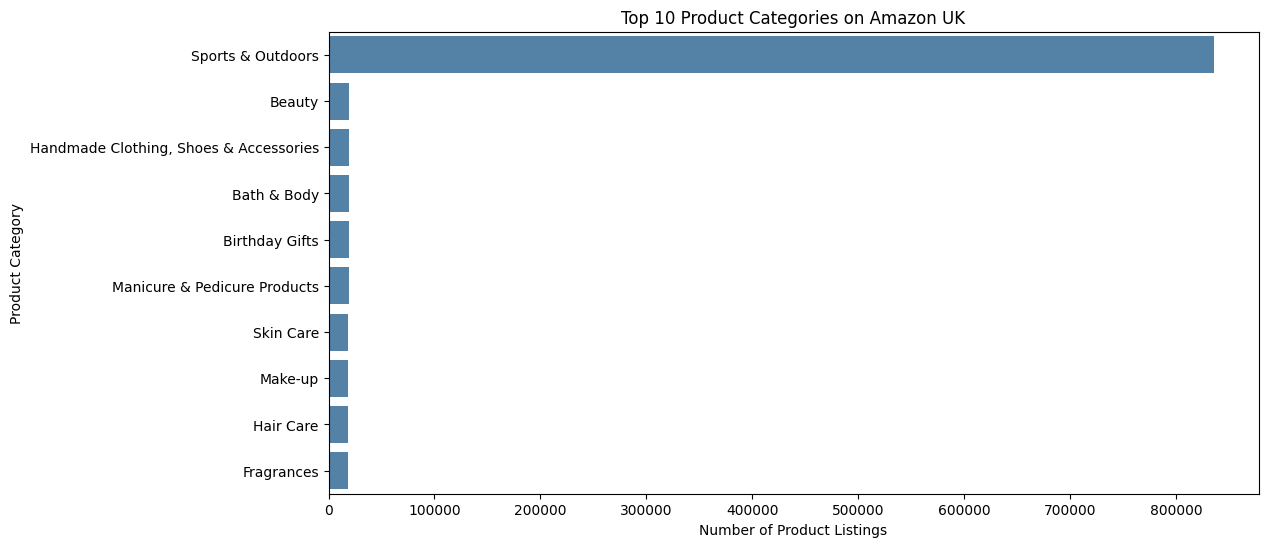

In [17]:
top_10_categories = category_frequency.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_categories.values,
    y=top_10_categories.index,
    color="steelblue"
)

plt.title("Top 10 Product Categories on Amazon UK")
plt.xlabel("Number of Product Listings")
plt.ylabel("Product Category")

plt.show()

### Interpretation of the Top 10 Product Categories

The bar chart shows that **Sports & Outdoors** is by far the most frequently
listed product category on Amazon UK, with **836,265 product listings**. It
accounts for approximately **34.22%** of all listings in the dataset.

The bar for Sports & Outdoors is substantially longer than every other bar,
demonstrating that the category distribution is highly concentrated.

The next four categories are:

- **Beauty:** 19,312 listings
- **Handmade Clothing, Shoes & Accessories:** 19,229 listings
- **Bath & Body:** 19,092 listings
- **Birthday Gifts:** 18,978 listings

The other categories in the top 10, including Manicure & Pedicure Products,
Skin Care, Make-up, Hair Care and Fragrances, have relatively similar listing
frequencies when compared with Sports & Outdoors.

Overall, the visualization confirms that Sports & Outdoors dominates the
dataset, while the remaining leading categories each represent a much smaller
share of total product listings.

These results describe product-listing frequency, not sales volume or the
number of unique customers.

In [18]:
df["price"]

0          21.99
1          23.99
2          21.99
3          31.99
4          17.99
           ...  
2443646    22.34
2443647    97.99
2443648    52.99
2443649    79.99
2443650    53.99
Name: price, Length: 2443651, dtype: float64

In [23]:
mean_price = df["price"].mean()
median_price = df["price"].median()
mode_price = df["price"].mode()[0]

print(mean_price)
print(median_price)
print(mode_price)

89.24380943923663
19.09
9.99


### Interpretation of product prices

The mean product price is approximately **£89.24**, while the median price is **£19.09** and the most frequently occurring price is **£9.99**.

The mean is considerably higher than the median and mode. This suggests that the price distribution is right-skewed: most products have relatively low
prices, while a smaller number of extremely expensive products pull the mean upward.

Therefore, the median of £19.09 is likely a better representation of the typical product price than the mean. The mode of £9.99 also suggests that
prices ending in `.99` are common in the dataset.

In [37]:
price_variance = df["price"].var()
price_std = df["price"].std()

print(f"Variance: {price_variance:.2f}")
print(f"Standard deviation: £{price_std:.2f}")

Variance: 119445.49
Standard deviation: £345.61


In [38]:
minimum_price = df["price"].min()
maximum_price = df["price"].max()
price_range = maximum_price - minimum_price

print(f"Minimum price: £{minimum_price:.2f}")
print(f"Maximum price: £{maximum_price:.2f}")
print(f"Price range: £{price_range:.2f}")

Minimum price: £0.00
Maximum price: £100000.00
Price range: £100000.00


In [ ]:
### Interpretation of Price Dispersion

The variance of product prices is **119,445.49**, while the standard deviation is approximately **£345.61**.
The standard deviation is considerably higher than both the mean price of **£89.24** and the median price of **£19.09**.
This indicates that product prices are widely dispersed.

The lowest recorded price is **£0.00**, while the highest is **£100,000.00**, producing a range of **£100,000.00**. The extremely high maximum price suggests
the presence of unusually expensive products or potential outliers.

The £0.00 minimum could represent free products, unavailable prices, placeholder values, or a possible data-quality issue. Further investigation would be
required before deciding whether these observations should be removed. 
    
Overall, the large standard deviation and range support the earlier conclusion that the price distribution is strongly right-skewed. Most products have
relatively low prices, while a small number of extremely expensive products 
increase the mean and overall spread.

In [27]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
price_IQR = Q3 - Q1

print(f"First quartile (Q1): £{Q1:.2f}")
print(f"Third quartile (Q3): £{Q3:.2f}")
print(f"Interquartile range (IQR): £{price_IQR:.2f}")

First quartile (Q1): £9.99
Third quartile (Q3): £45.99
Interquartile range (IQR): £36.00


### Interpretation of the Interquartile Range

The first quartile (**Q1**) is **£9.99**. This means that approximately 25% of
the products are priced at or below £9.99.

The third quartile (**Q3**) is **£45.99**. This means that approximately 75% of
the products are priced at or below £45.99.

The interquartile range (**IQR**) is **£36.00**, calculated as:

**IQR = Q3 − Q1 = £45.99 − £9.99 = £36.00**

Therefore, the middle 50% of product prices fall between **£9.99 and £45.99**.

Unlike the total price range of £100,000, the IQR is not strongly influenced
by extremely expensive products. It therefore provides a more representative
description of the spread of typical product prices.

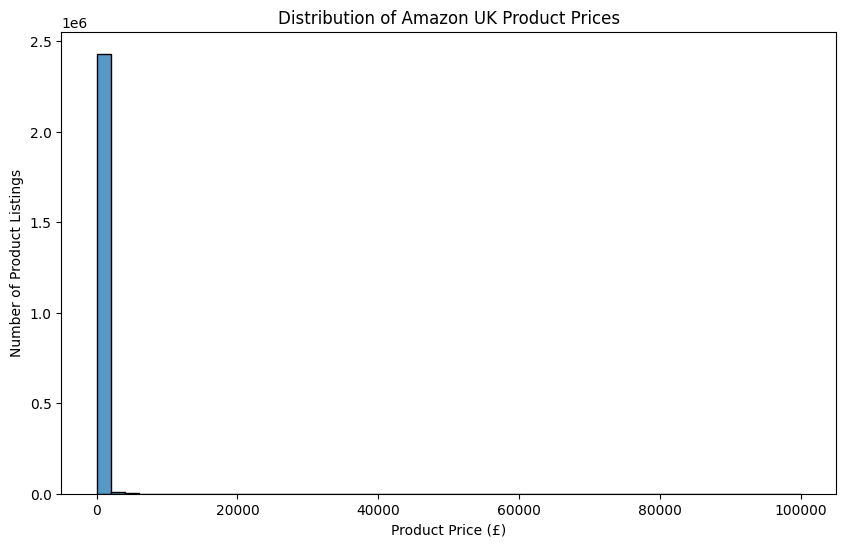

In [28]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="price",
    bins=50
)

plt.title("Distribution of Amazon UK Product Prices")
plt.xlabel("Product Price (£)")
plt.ylabel("Number of Product Listings")

plt.show()

### Interpretation of the Complete Price Histogram

The complete histogram shows that the product-price distribution is extremely
right-skewed. Almost all product listings are concentrated near the lower end
of the price scale, while a small number of exceptionally expensive products
extend the horizontal axis to £100,000.

Because the full price range is displayed, the majority of prices are compressed
into the first bar on the left. This makes the detailed distribution of typical
product prices difficult to observe in the complete histogram.

The very long right-hand tail and the concentration of listings at lower prices
support the earlier finding that the mean price of £89.24 is pulled upward by
unusually expensive products. The median price of £19.09 is therefore a more
representative measure of a typical product price.

A focused histogram up to the 95th percentile is useful for examining the
distribution of the majority of product prices more clearly.

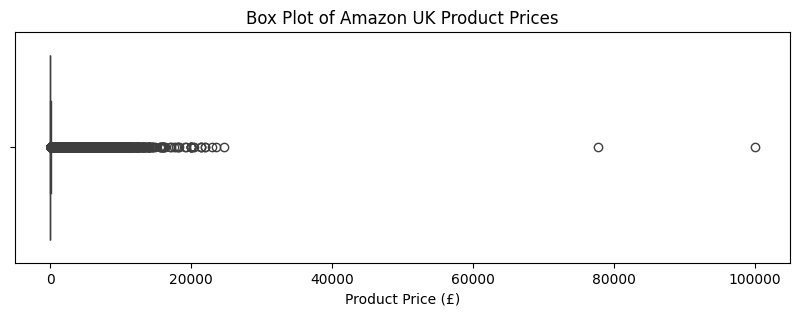

In [29]:
plt.figure(figsize=(10, 3))

sns.boxplot(
    data=df,
    x="price"
)

plt.title("Box Plot of Amazon UK Product Prices")
plt.xlabel("Product Price (£)")

plt.show()

### Interpretation of the Complete Price Box Plot

The complete box plot confirms that the product-price distribution is strongly
right-skewed. The central box is compressed near the lower end of the horizontal
axis because most products have relatively low prices compared with the most
expensive products.

The middle 50% of product prices fall between **£9.99 (Q1)** and **£45.99 (Q3)**,
with a median price of **£19.09**. However, these values are difficult to see in
the complete box plot because the horizontal axis extends to **£100,000**.

Using the IQR rule, prices above approximately **£99.99** are classified as
potential upper outliers:

**Upper boundary = Q3 + 1.5 × IQR**

**Upper boundary = £45.99 + 1.5 × £36.00 = £99.99**

The numerous points to the right of the box represent products priced above this
boundary. The two points near **£78,000** and **£100,000** are especially extreme.

This visualization supports the conclusion that unusually expensive products
increase the mean price and produce a long right-hand tail. A focused box plot
is therefore also useful for examining the price distribution of the majority
of products more clearly.

In [34]:
# Calculate the price below which 95% of products fall
price_95th_percentile = df["price"].quantile(0.95)

# Keep products priced at or below the 95th percentile
typical_prices = df[
    df["price"] <= price_95th_percentile
].copy()

print(f"95th percentile: £{price_95th_percentile:.2f}")
print("Number of products included:", len(typical_prices))

95th percentile: £349.50
Number of products included: 2321469


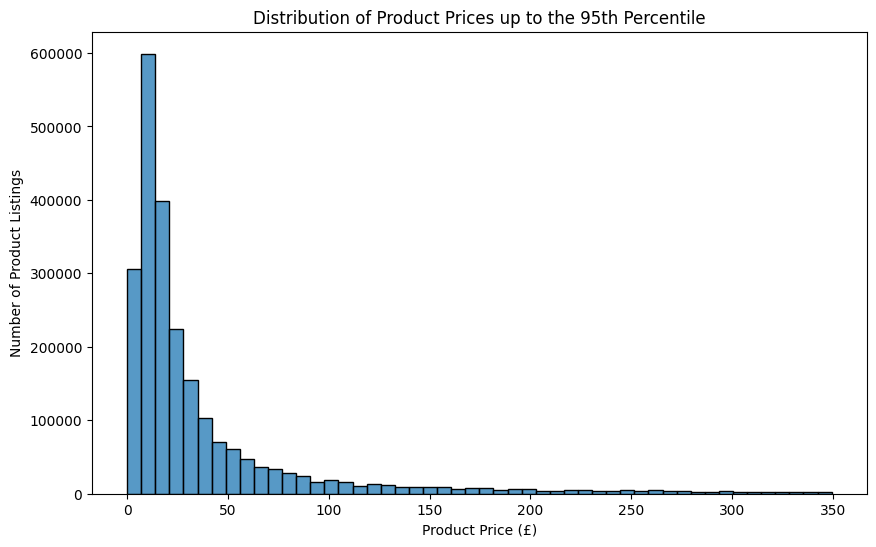

In [35]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=typical_prices,
    x="price",
    bins=50
)

plt.title("Distribution of Product Prices up to the 95th Percentile")
plt.xlabel("Product Price (£)")
plt.ylabel("Number of Product Listings")

plt.show()

### Interpretation of the Focused Price Histogram

The focused histogram displays product prices up to the 95th percentile.
Most product listings are concentrated among the lower price ranges, particularly
below approximately £50.

As prices increase, the number of listings gradually decreases, creating a long
tail toward the right. Therefore, the price distribution remains strongly
right-skewed even after temporarily excluding the highest 5% of prices from the
visualization.

This supports the earlier finding that the mean price of £89.24 is influenced
by expensive products and that the median price of £19.09 provides a better
representation of a typical product price.

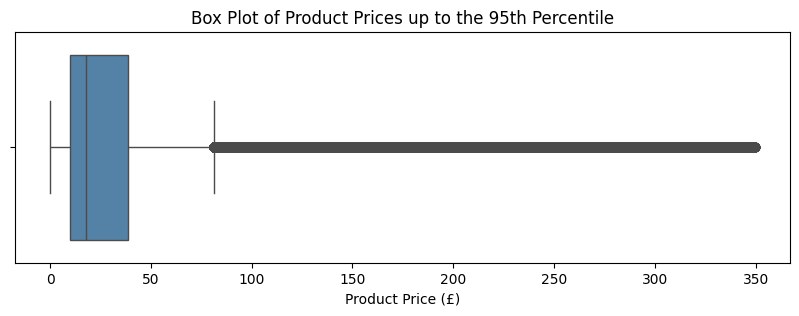

In [36]:
plt.figure(figsize=(10, 3))

sns.boxplot(
    data=typical_prices,
    x="price",
    color="steelblue"
)

plt.title("Box Plot of Product Prices up to the 95th Percentile")
plt.xlabel("Product Price (£)")

plt.show()

### Interpretation of the Focused Price Box Plot

This box plot displays product prices up to the 95th percentile. The highest
5% of prices are temporarily excluded from this visualization, allowing the
distribution of the majority of products to be examined more clearly.

The box and median are concentrated toward the lower end of the price scale.
The right whisker is considerably longer than the left whisker, and numerous
potential outliers extend toward approximately £350.

This shows that the price distribution remains strongly right-skewed even after
excluding the highest 5% of prices. Most products have relatively low prices,
while progressively fewer products appear at higher price levels.

The points beyond the right whisker are potential outliers according to the IQR
rule calculated by the box plot for this focused subset. They are not necessarily
incorrect observations; they are simply unusually high compared with the main
concentration of prices in the focused data.

In [42]:
df["stars"].head(10)

0    4.7
1    4.7
2    4.7
3    4.7
4    4.6
5    4.7
6    4.7
7    4.7
8    4.7
9    4.5
Name: stars, dtype: float64

In [43]:
rating_frequency = (
    df["stars"]
    .value_counts()
    .sort_index()
)

rating_frequency

stars
0.0    1225641
1.0       8484
1.1          3
1.2         23
1.3         78
1.4        149
1.5        404
1.6        147
1.7        177
1.8        249
1.9        300
2.0       3901
2.1        540
2.2        602
2.3        734
2.4       1060
2.5       2103
2.6       1579
2.7       2104
2.8       2306
2.9       3341
3.0      12819
3.1       4679
3.2       5771
3.3       8269
3.4      10355
3.5      14673
3.6      16219
3.7      21137
3.8      27876
3.9      36555
4.0      66089
4.1      65115
4.2      86871
4.3     112564
4.4     136165
4.5     151577
4.6     136995
4.7      94566
4.8      41858
4.9      11081
5.0     128492
Name: count, dtype: int64

In [44]:
mean_rating = df["stars"].mean()
median_rating = df["stars"].median()
mode_rating = df["stars"].mode()[0]

print(f"Mean rating: {mean_rating:.2f}")
print(f"Median rating: {median_rating:.2f}")
print(f"Mode rating: {mode_rating:.2f}")

Mean rating: 2.15
Median rating: 0.00
Mode rating: 0.00


### Interpretation of Product Ratings

The mean product rating is approximately **2.15 stars**, while both the median
and mode are **0.00 stars**.

The median of 0.00 means that at least half of the product listings have a
recorded star value of zero. The mode of 0.00 confirms that zero is the most
frequently occurring value in the `stars` column.

However, a value of zero may represent a product that has not yet received a
customer rating rather than a genuine zero-star review. Therefore, the mean of
2.15 should not automatically be interpreted as evidence that customers are
generally dissatisfied with the products.

The large number of zero values pulls the mean rating downward. A separate
analysis of products with ratings greater than zero would provide a clearer
picture of how customers rated products that actually received ratings.

In [45]:
rating_variance = df["stars"].var()
rating_std = df["stars"].std()

print(f"Rating variance: {rating_variance:.2f}")
print(f"Rating standard deviation: {rating_std:.2f}")

Rating variance: 4.82
Rating standard deviation: 2.19


### Interpretation of Rating Dispersion

The variance of product ratings is **4.82**, while the standard deviation is
approximately **2.19 stars**.

The standard deviation indicates that product rating values typically differ
from the mean rating of **2.15 stars** by approximately **2.19 stars**.

This relatively large spread is influenced by the substantial number of products
with a recorded rating of **0.00**, together with products having much higher
ratings.

However, zero values may represent products without recorded customer ratings
rather than genuine zero-star reviews. Therefore, the calculated variance and
standard deviation describe the distribution of the `stars` column as recorded,
but they may not accurately represent variation in actual customer opinions.

A separate analysis of products with ratings greater than zero would provide a
clearer understanding of the variation among products that received customer
ratings.

In [46]:
minimum_rating = df["stars"].min()
maximum_rating = df["stars"].max()
rating_range = maximum_rating - minimum_rating

print(f"Minimum rating: {minimum_rating:.2f}")
print(f"Maximum rating: {maximum_rating:.2f}")
print(f"Rating range: {rating_range:.2f}")

Minimum rating: 0.00
Maximum rating: 5.00
Rating range: 5.00


In [47]:
rating_Q1 = df["stars"].quantile(0.25)
rating_Q3 = df["stars"].quantile(0.75)
rating_IQR = rating_Q3 - rating_Q1

print(f"First quartile (Q1): {rating_Q1:.2f}")
print(f"Third quartile (Q3): {rating_Q3:.2f}")
print(f"Rating IQR: {rating_IQR:.2f}")

First quartile (Q1): 0.00
Third quartile (Q3): 4.40
Rating IQR: 4.40


### Interpretation of the Rating Interquartile Range

The first quartile (**Q1**) is **0.00 stars**. This means that approximately
25% of the product listings have a recorded rating at or below 0.00. Since
ratings cannot be negative, this indicates that at least 25% of the products
have a recorded value of zero.

The third quartile (**Q3**) is **4.40 stars**. This means that approximately
75% of the product listings have a recorded rating at or below 4.40 stars.

The interquartile range is calculated as:

**IQR = Q3 − Q1**

**IQR = 4.40 − 0.00 = 4.40 stars**

Therefore, the middle 50% of the recorded rating values lie between **0.00 and
4.40 stars**. This is a wide interval and shows considerable variation in the
`stars` column.

However, the large IQR is strongly influenced by the many zero values. If zero
represents products without customer ratings, the IQR describes a mixture of
unrated and rated products rather than variation in actual customer opinions
alone.

In [48]:
rating_skewness = df["stars"].skew()
rating_kurtosis = df["stars"].kurt()

print(f"Rating skewness: {rating_skewness:.2f}")
print(f"Rating kurtosis: {rating_kurtosis:.2f}")

Rating skewness: 0.08
Rating kurtosis: -1.93


### Interpretation of Rating Skewness and Kurtosis

The skewness of the recorded product ratings is **0.08**. Because this value is
close to zero, the overall distribution has very little numerical skewness and
is approximately balanced between lower and higher values.

However, low skewness does not necessarily mean that the distribution is normal
or bell-shaped. The substantial number of zero values and the concentration of
other observations among higher ratings can balance each other and produce
skewness close to zero.

The kurtosis is **−1.93**. This negative value indicates a relatively flat
distribution with lighter tails than a normal distribution. This type of
distribution is described as **platykurtic**.

The shape is influenced by the restricted rating scale of 0 to 5 stars and by
the large number of products recorded with zero stars. Therefore, these results
describe the `stars` column as recorded and should not be interpreted solely as
a distribution of genuine customer opinions.

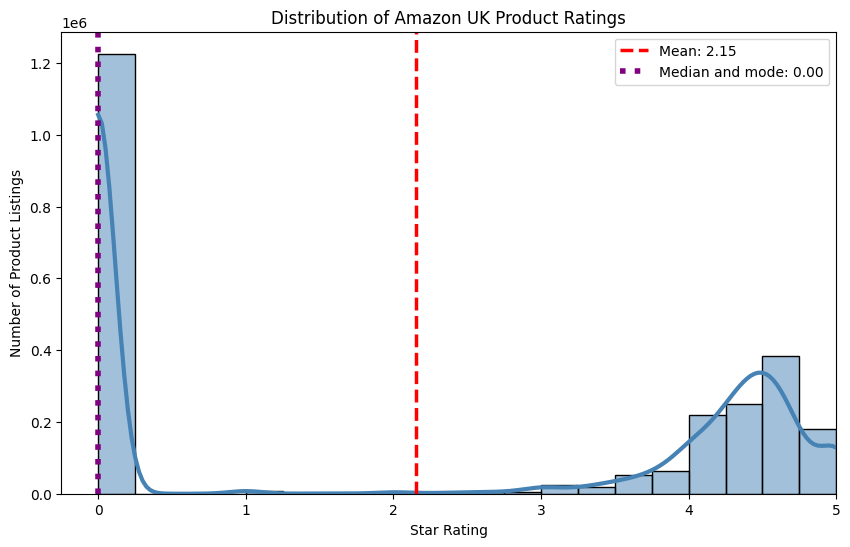

In [53]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="stars",
    bins=20,
    kde=True,
    color="steelblue",
    line_kws={"linewidth": 3},
    kde_kws={"clip": (0, 5)}
)

# Mean line
plt.axvline(
    mean_rating,
    color="red",
    linestyle="--",
    linewidth=2.5,
    label=f"Mean: {mean_rating:.2f}"
)

# Combined median and mode line because both equal zero
plt.axvline(
    median_rating,
    color="purple",
    linestyle=":",
    linewidth=4,
    label=f"Median and mode: {median_rating:.2f}"
)

plt.title("Distribution of Amazon UK Product Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Product Listings")

# Extend slightly below zero so the zero line is visible
plt.xlim(-0.25, 5)

plt.legend()
plt.show()

### Interpretation of the Product-Rating Distribution

The histogram shows two strong concentrations in the recorded star values. A
very large number of product listings have a value of **0.00**, while many of
the positively rated products are concentrated between approximately **4 and
5 stars**.

The mean rating is **2.15 stars**, while both the median and mode are **0.00**.
The median and mode lines therefore overlap at zero.

The calculated skewness is **0.08**, which is close to zero and indicates very
little overall numerical skewness. However, the histogram is not normally
distributed or bell-shaped. The concentration at zero and the separate
concentration among high ratings balance each other, producing a skewness value
close to zero.

The kurtosis of **−1.93** indicates a relatively flat, or platykurtic,
distribution compared with a normal distribution.

The zero values may represent products without recorded ratings rather than
genuine zero-star reviews. Therefore, the distribution should not be
interpreted as evidence that a large number of customers gave products
zero-star ratings.